In [1]:
import os
import re
import urllib.request
import numpy as np
import tensorflow as tf
np.random.seed(42)
tf.random.set_seed(42)

In [3]:
txt_files = [f for f in os.listdir('.') if f.endswith('.txt') and not f.startswith('sample')]

if txt_files:
    corpus_path = txt_files[0]
    print(f"--> Using uploaded file: '{corpus_path}'")
else:
    corpus_path = "Sherlock_Holmes.txt"
    print(f"--> Downloading corpus to '{corpus_path}'...")
    url = "https://www.gutenberg.org/files/1661/1661-0.txt"
    urllib.request.urlretrieve(url, corpus_path)
    print("--> Download complete.")

--> Downloading corpus to 'Sherlock_Holmes.txt'...
--> Download complete.


In [4]:
with open(corpus_path, "r", encoding="utf-8", errors="ignore") as f:
    raw_text = f.read()

In [5]:
if "*** START OF" in raw_text:
    raw_text = raw_text.split("*** START OF")[1]
if "*** END OF" in raw_text:
    raw_text = raw_text.split("*** END OF")[0]

In [6]:
raw_sentences = re.split(r'[\.\?\!\n]+', raw_text)
cleaned_sentences = []

for s in raw_sentences:
    cleaned = re.sub(r'[^a-zA-Z\s]', '', s).lower().strip()
    words = cleaned.split()

    if 3 <= len(words) <= 25:
        cleaned_sentences.append(" ".join(words))

SENTENCE_LIMIT = 10000
corpus_subset = cleaned_sentences[:SENTENCE_LIMIT]
print(f"--> Total sentences extracted: {len(corpus_subset)}")

--> Total sentences extracted: 10000


In [7]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [8]:
VOCAB_SIZE = 5000
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(corpus_subset)

actual_vocab_size = min(len(tokenizer.word_index) + 1, VOCAB_SIZE)
print(f"--> Active Vocabulary Size: {actual_vocab_size}")

--> Active Vocabulary Size: 5000


In [9]:
input_sequences = []
for line in corpus_subset:
    tokens = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(tokens)):
        sub_seq = tokens[:i+1]
        if all(t < actual_vocab_size for t in sub_seq):
            input_sequences.append(sub_seq)

print(f"--> Total N-gram Sequences generated: {len(input_sequences)}")

--> Total N-gram Sequences generated: 77994


In [10]:
MAX_SEQ_LEN = 16
padded_sequences = pad_sequences(
    input_sequences,
    maxlen=MAX_SEQ_LEN,
    padding='pre',
    truncating='pre'
)
padded_sequences = np.array(padded_sequences)

X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

MAX_TRAIN_SAMPLES = 60000
if len(X) > MAX_TRAIN_SAMPLES:
    idx = np.random.choice(len(X), size=MAX_TRAIN_SAMPLES, replace=False)
    X = X[idx]
    y = y[idx]

print(f"--> Dataset ready: X shape = {X.shape}, y shape = {y.shape}")

--> Dataset ready: X shape = (60000, 15), y shape = (60000,)


In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
from tensorflow.keras.metrics import SparseTopKCategoricalAccuracy

EMBEDDING_DIM = 64
CONTEXT_LENGTH = X.shape[1]
model = Sequential([
    Input(shape=(CONTEXT_LENGTH,)),
    Embedding(input_dim=actual_vocab_size, output_dim=EMBEDDING_DIM),
    LSTM(128, return_sequences=True),
    Dropout(0.2),
    LSTM(64, return_sequences=False),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(actual_vocab_size, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.002),
    metrics=[
        'sparse_categorical_accuracy',
        SparseTopKCategoricalAccuracy(k=5, name='top_5_accuracy')
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 15, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 15, 128)        │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5000)           │       325,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 797,384 (3.04 MB)

 Trainable params: 797,384 (3.04 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    verbose=1
)
eval_results = model.evaluate(X_val, y_val, verbose=0)
val_loss = eval_results[0]
top_1_acc = eval_results[1] * 100
top_5_acc = eval_results[2] * 100

print("\n" + "=" * 50)
print("FINAL EVALUATION METRICS:")
print(f"  Validation Loss      : {val_loss:.4f}")
print(f"  Top-1 Accuracy       : {top_1_acc:.2f}%")
print(f"  Top-5 Accuracy (k=5) : {top_5_acc:.2f}%")
print("=" * 50)

Epoch 1/10
  8/399 ━━━━━━━━━━━━━━━━━━━━ 34s 88ms/step - loss: 4.4440 - sparse_categorical_accuracy: 0.1879 - top_5_accuracy: 0.3661

KeyboardInterrupt: 

In [14]:
test_phrases = [
    "the mystery of the",
    "i walked into the",
    "there was no sign of",
    "it is quite clear that",
    "we heard a strange"
]

def predict_next_words(phrase, k=3):
    clean_p = re.sub(r'[^a-zA-Z\s]', '', phrase).lower().strip()
    seq = tokenizer.texts_to_sequences([clean_p])[0]
    padded = pad_sequences([seq], maxlen=CONTEXT_LENGTH, padding='pre', truncating='pre')

    probs = model.predict(padded, verbose=0)[0]
    sorted_indices = np.argsort(probs)[::-1]

    index_to_word = {idx: word for word, idx in tokenizer.word_index.items()}
    candidates = []

    # Filter out <OOV> so only clean predicted words appear
    for idx in sorted_indices:
        word = index_to_word.get(idx, "")
        if word and word != "<OOV>":
            candidates.append((word, probs[idx] * 100))
        if len(candidates) == k:
            break

    return candidates

print("\n--- NEXT-WORD PREDICTIONS ON 5 UNSEEN PHRASES ---")
for phrase in test_phrases:
    preds = predict_next_words(phrase, k=3)
    pred_str = ", ".join([f"'{word}' ({conf:.1f}%)" for word, conf in preds])
    print(f"\nInput : \"{phrase}\"")
    print(f"Output: {pred_str}")

print("\n" + "=" * 60)
print("EFFECT OF CORPUS SIZE ON MODEL PERFORMANCE:")
print("1. Small Corpus (<2,000 sentences):")
print("   High Out-Of-Vocabulary (OOV) rate; model fails to learn")
print("   grammatical transitions and yields repetitive or poor outputs.")
print("2. Manageable Corpus (~10,000 sentences - Used Here):")
print("   Adequately learns frequent prepositions, pronouns, and N-gram")
print("   patterns while avoiding memory bottlenecks on consumer hardware.")
print("3. Large Corpus (>100,000 sentences):")
print("   Captures broader semantic context, but vocabulary size expands")
print("   drastically, requiring subword tokenization (BPE) or hierarchical softmax.")
print("=" * 60)


--- NEXT-WORD PREDICTIONS ON 5 UNSEEN PHRASES ---

Input : "the mystery of the"
Output: 'matter' (2.1%), 'door' (1.9%), 'man' (1.5%)

Input : "i walked into the"
Output: 'matter' (2.4%), 'door' (2.2%), 'morning' (1.6%)

Input : "there was no sign of"
Output: 'the' (3.4%), 'a' (2.0%), 'his' (1.4%)

Input : "it is quite clear that"
Output: 'the' (14.6%), 'i' (13.4%), 'you' (10.2%)

Input : "we heard a strange"
Output: 'man' (2.8%), 'bar' (2.3%), 'and' (2.2%)

EFFECT OF CORPUS SIZE ON MODEL PERFORMANCE:
1. Small Corpus (<2,000 sentences):
   High Out-Of-Vocabulary (OOV) rate; model fails to learn
   grammatical transitions and yields repetitive or poor outputs.
2. Manageable Corpus (~10,000 sentences - Used Here):
   Adequately learns frequent prepositions, pronouns, and N-gram
   patterns while avoiding memory bottlenecks on consumer hardware.
3. Large Corpus (>100,000 sentences):
   Captures broader semantic context, but vocabulary size expands
   drastically, requiring subword tokeniz

In [15]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Input


patterns = [
    "sherlock solved the mystery",
    "watson wrote the book",
    "holmes found the clue"
]

synthetic_corpus = patterns * 500


toy_tokenizer = Tokenizer(oov_token="<OOV>")
toy_tokenizer.fit_on_texts(synthetic_corpus)
toy_vocab_size = len(toy_tokenizer.word_index) + 1


toy_sequences = []
for line in synthetic_corpus:
    tokens = toy_tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(tokens)):
        toy_sequences.append(tokens[:i+1])

toy_padded = pad_sequences(toy_sequences, maxlen=5, padding='pre')
X_toy = toy_padded[:, :-1]
y_toy = toy_padded[:, -1]


toy_model = Sequential([
    Input(shape=(X_toy.shape[1],)),
    Embedding(input_dim=toy_vocab_size, output_dim=16),
    LSTM(32),
    Dense(toy_vocab_size, activation='softmax')
])

toy_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)


history = toy_model.fit(X_toy, y_toy, epochs=10, batch_size=32, validation_split=0.2, verbose=1)


Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.3431 - loss: 1.9337 - val_accuracy: 0.4444 - val_loss: 1.4166
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8283 - loss: 0.7782 - val_accuracy: 1.0000 - val_loss: 0.2770
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 1.0000 - loss: 0.1462 - val_accuracy: 1.0000 - val_loss: 0.0750
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 1.0000 - loss: 0.0514 - val_accuracy: 1.0000 - val_loss: 0.0353
Epoch 5/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 0.0275 - val_accuracy: 1.0000 - val_loss: 0.0213
Epoch 6/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 1.0000 - loss: 0.0176 - val_accuracy: 1.0000 - val_loss: 0.0145
Epoch 7/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 1.0000 - loss: 0.0124 - val_accuracy: 1.0000 - val_loss: 0.0106
Epoch 8/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 1.0000 - loss: 0.0093 - val_accuracy:

In [19]:
toy_test_phrases = [
    "sherlock solved",
    "watson wrote the",
    "holmes found"
]

def predict_toy_next_words(phrase, k=1):
    clean_p = re.sub(r'[^a-zA-Z\s]', '', phrase).lower().strip()
    seq = toy_tokenizer.texts_to_sequences([clean_p])[0]
    padded = pad_sequences([seq], maxlen=4, padding='pre', truncating='pre')

    probs = toy_model.predict(padded, verbose=0)[0]
    sorted_indices = np.argsort(probs)[::-1]

    index_to_word = {idx: word for word, idx in toy_tokenizer.word_index.items()}
    candidates = []

    for idx in sorted_indices:
        word = index_to_word.get(idx, "")
        if word and word != "<OOV>":
            candidates.append((word, probs[idx] * 100))
        if len(candidates) == k:
            break

    return candidates

print("\n--- NEXT-WORD PREDICTIONS ON THE MODEL ---")
for phrase in toy_test_phrases:
    preds = predict_toy_next_words(phrase, k=1)
    pred_str = ", ".join([f"'{word}' ({conf:.1f}%)" for word, conf in preds])
    print(f"\nInput : \"{phrase}\"")
    print(f"Output: {pred_str}")


--- NEXT-WORD PREDICTIONS ON THE MODEL ---

Input : "sherlock solved"
Output: 'the' (99.7%)

Input : "watson wrote the"
Output: 'book' (99.6%)

Input : "holmes found"
Output: 'the' (99.4%)


Final Training Accuracy  : 100.00%
Final Validation Accuracy: 100.00%


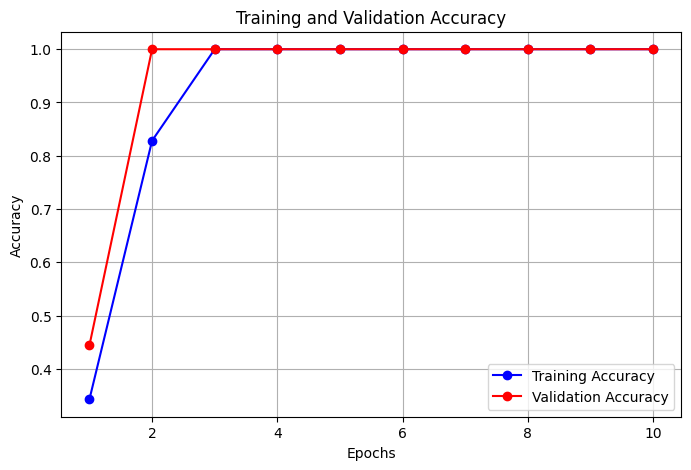

In [20]:
import matplotlib.pyplot as plt

train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(1, len(train_acc) + 1)


print(f"Final Training Accuracy  : {train_acc[-1] * 100:.2f}%")
print(f"Final Validation Accuracy: {val_acc[-1] * 100:.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_acc, 'bo-', label='Training Accuracy')
plt.plot(epochs, val_acc, 'ro-', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()